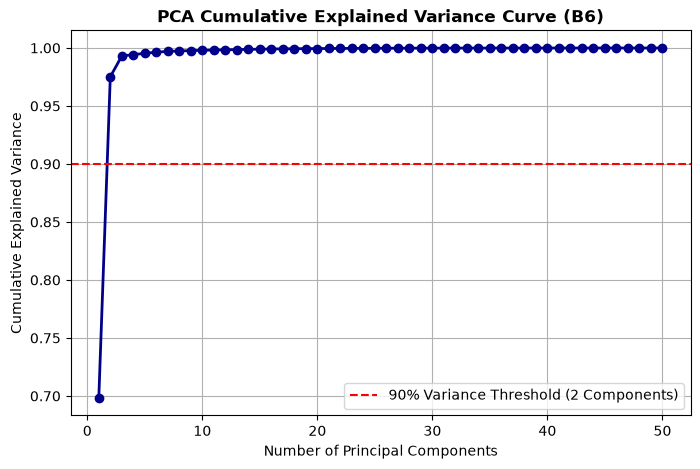

--- B6 DIMENSIONALITY EVIDENCE ---
Number of components carrying >= 90% of variance: 2


In [1]:
import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Setup paths
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
clean_meta_path = os.path.join(repo_root, "data", "clean", "metadata_clean.parquet")
raw_wave_path = os.path.join(repo_root, "data", "raw", "waveforms.hdf5")

df = pd.read_parquet(clean_meta_path)

# Subsample 1,000 traces for PCA fit
sample_df = df.sample(n=min(1000, len(df)), random_state=42)

trace_matrix = []
with h5py.File(raw_wave_path, "r") as hf:
    data_grp = hf["data"]
    for _, row in sample_df.iterrows():
        b_val, t_idx = str(row["bucket"]).strip(), int(row["tindex"])
        b_key = b_val if b_val.startswith("bucket") else f"bucket{b_val}"
        if b_key in data_grp and t_idx < data_grp[b_key].shape[0]:
            tr = np.array(data_grp[b_key][t_idx], dtype=np.float32)
            trace_matrix.append(tr.flatten())  # Flatten 3x1500 to 4500 1D vector

X = np.array(trace_matrix)

# Fit PCA
n_components = 50
pca = PCA(n_components=n_components)
pca.fit(X)

cum_variance = np.cumsum(pca.explained_variance_ratio_)
comp_90 = np.argmax(cum_variance >= 0.90) + 1

# Plot Cumulative Variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_components + 1), cum_variance, marker="o", color="darkblue", linewidth=2)
plt.axhline(y=0.90, color="r", linestyle="--", label=f"90% Variance Threshold ({comp_90} Components)")
plt.title("PCA Cumulative Explained Variance Curve (B6)", fontsize=12, fontweight="bold")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

print("--- B6 DIMENSIONALITY EVIDENCE ---")
print(f"Number of components carrying >= 90% of variance: {comp_90}")